# Generación — Notebook 01
## DCGAN para generar rostros humanos sintéticos (PyTorch)

Una **Red Generativa Adversaria** (GAN; Goodfellow et al., 2014) enfrenta a dos redes:

* **Generador G(z)**: transforma un vector de ruido aleatorio *z* ∈ ℝ¹⁰⁰ (el **espacio latente**) en una imagen.
* **Discriminador D(x)**: recibe una imagen y estima la probabilidad de que sea **real** (del dataset) y no **falsa** (de G).

Ambas se entrenan a la vez en un juego de suma cero (minimax):

$$\min_G \max_D \; \mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1 - D(G(z)))]$$

D aprende a distinguir lo real de lo falso y G aprende a engañar a D. En el equilibrio, G reproduce la distribución de los datos y D no puede hacer nada mejor que responder 0.5.

La **DCGAN** (Radford, Metz y Chintala, 2016) es la versión convolucional estable de la GAN, y es la arquitectura del artículo de referencia *Implementing a GAN/DCGAN to Draw Human Faces*: convoluciones transpuestas en G, convoluciones con paso 2 en D (sin *pooling*), Batch Normalization, ReLU en G, LeakyReLU en D, tanh a la salida de G e inicialización N(0, 0.02).

**Datos.** Base de rostros **ORL / AT&T** (Olivetti Research Laboratory): 400 fotografías de 40 personas, escala de grises, de uso académico. Se usa porque es pequeña y permite entrenar en CPU; en Colab con GPU el mismo código funciona con CelebA (202 599 rostros a color) cambiando la celda de datos.

> Google Colab: `Entorno de ejecución → Ejecutar todas`. Con GPU tarda ~2 min; en CPU ~20 min.

In [1]:
import os, time, json, math, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
for d in ("data", "figures", "results", "modelos"): os.makedirs(d, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110})
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.15.0+cu132 | dispositivo: cpu


## 1. Preparación de los datos
1. Descarga de las 400 imágenes (92×112 px).
2. Recorte central cuadrado de 92×92 (se descarta frente y mentón sobrantes) y redimensionado a **64×64**, la resolución de la DCGAN original.
3. Normalización a **[−1, 1]**, el rango de la salida tanh del generador.
4. Aumento de datos: espejo horizontal aleatorio en cada lote (duplica la variedad efectiva sin alterar la identidad facial).

Dataset: (400, 1, 64, 64) | rango: -1.0 a 1.0


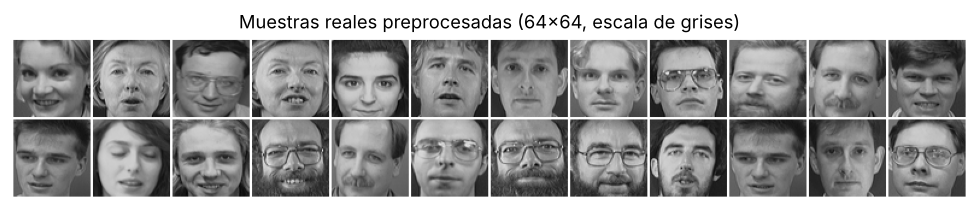

In [2]:
DATA_DIR = "data/orl"
if not os.path.isdir(DATA_DIR):
    BASE = "https://raw.githubusercontent.com/milk-abc/PCA-KPCA/master/att_faces"
    jobs = [(f"{BASE}/s{s}/{i}.pgm", f"{DATA_DIR}/s{s}/{i}.pgm") for s in range(1, 41) for i in range(1, 11)]
    for _, dst in jobs: os.makedirs(os.path.dirname(dst), exist_ok=True)
    with ThreadPoolExecutor(16) as ex: list(ex.map(lambda j: urllib.request.urlretrieve(*j), jobs))

def load_faces(root, size=64):
    imgs = []
    for s in range(1, 41):
        for i in range(1, 11):
            im = Image.open(f"{root}/s{s}/{i}.pgm")                    # 92 x 112, escala de grises
            im = im.crop((0, 10, 92, 102)).resize((size, size), Image.LANCZOS)
            imgs.append(np.asarray(im, dtype=np.float32))
    x = np.stack(imgs)[:, None] / 127.5 - 1.0                          # (400, 1, 64, 64) en [-1, 1]
    return torch.tensor(x)

X = load_faces(DATA_DIR)
print("Dataset:", tuple(X.shape), "| rango:", float(X.min()), "a", float(X.max()))

def grid(imgs, nrow=8, pad=2):
    """Convierte un tensor (N,1,H,W) en [-1,1] en una cuadrícula NumPy para mostrar."""
    imgs = (imgs.detach().cpu().clamp(-1, 1) + 1) / 2
    n, _, h, w = imgs.shape; ncol = math.ceil(n / nrow)
    g = np.ones((ncol * (h + pad) + pad, nrow * (w + pad) + pad))
    for k in range(n):
        r, c = divmod(k, nrow)
        g[pad + r * (h + pad): pad + r * (h + pad) + h, pad + c * (w + pad): pad + c * (w + pad) + w] = imgs[k, 0].numpy()
    return g

plt.figure(figsize=(9, 3.6)); plt.imshow(grid(X[torch.randperm(400)[:24]], 12), cmap="gray"); plt.axis("off")
plt.title("Muestras reales preprocesadas (64×64, escala de grises)"); plt.tight_layout()
plt.savefig("figures/01_datos_reales.png", bbox_inches="tight"); plt.show()

## 2. Arquitectura DCGAN

| Generador | Salida | | Discriminador | Salida |
|---|---|---|---|---|
| z ∈ ℝ¹⁰⁰ (100×1×1) | | | Imagen 1×64×64 | |
| ConvT 4×4, BN, ReLU | 256×4×4 | | Conv 4×4 s2, LeakyReLU 0.2 | 32×32×32 |
| ConvT 4×4 s2, BN, ReLU | 128×8×8 | | Conv 4×4 s2, BN, LeakyReLU | 64×16×16 |
| ConvT 4×4 s2, BN, ReLU | 64×16×16 | | Conv 4×4 s2, BN, LeakyReLU | 128×8×8 |
| ConvT 4×4 s2, BN, ReLU | 32×32×32 | | Conv 4×4 s2, BN, LeakyReLU | 256×4×4 |
| ConvT 4×4 s2, **tanh** | 1×64×64 | | Conv 4×4 → logit | 1 |

In [3]:
NZ, NGF, NDF = 100, 32, 32

class Generator(nn.Module):
    """G: ruido z (100) -> imagen 1x64x64 mediante convoluciones transpuestas (cada una duplica la resolución)."""
    def __init__(self, nz=NZ, ngf=NGF, nc=1):
        super().__init__()
        def up(i, o): return [nn.ConvTranspose2d(i, o, 4, 2, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.net = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 8), nn.ReLU(True),  # 4x4
            *up(ngf * 8, ngf * 4), *up(ngf * 4, ngf * 2), *up(ngf * 2, ngf),                                 # 8, 16, 32
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False), nn.Tanh())                                     # 64x64
    def forward(self, z): return self.net(z)

class Discriminator(nn.Module):
    """D: imagen 1x64x64 -> logit (real/falsa) con convoluciones de paso 2 en lugar de pooling."""
    def __init__(self, ndf=NDF, nc=1):
        super().__init__()
        def down(i, o, bn=True):
            return [nn.Conv2d(i, o, 4, 2, 1, bias=False)] + ([nn.BatchNorm2d(o)] if bn else []) + [nn.LeakyReLU(0.2, True)]
        self.net = nn.Sequential(*down(nc, ndf, bn=False), *down(ndf, ndf * 2), *down(ndf * 2, ndf * 4), *down(ndf * 4, ndf * 8),
                                 nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False))
    def forward(self, x): return self.net(x).view(-1)

def weights_init(m):
    """Inicialización DCGAN: pesos N(0, 0.02); BatchNorm con escala N(1, 0.02)."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)): nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d): nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

G, D = Generator().to(device), Discriminator().to(device)
G.apply(weights_init); D.apply(weights_init)
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"Generador: {n_params(G):,} parámetros | Discriminador: {n_params(D):,} parámetros")
print("Salida de G para un lote de 2:", tuple(G(torch.randn(2, NZ, 1, 1, device=device)).shape))

Generador: 1,099,200 parámetros | Discriminador: 693,632 parámetros
Salida de G para un lote de 2: (2, 1, 64, 64)


## 3. Entrenamiento adversarial
En cada iteración:
1. **Paso de D**: maximiza log D(x) + log(1 − D(G(z))) → pérdida BCE con etiqueta 0.9 para las reales (*label smoothing* unilateral, evita que D se vuelva demasiado confiado) y 0 para las falsas.
2. **Paso de G**: en lugar de minimizar log(1 − D(G(z))), que satura al inicio, maximiza log D(G(z)) (pérdida «no saturante» de Goodfellow) → BCE con etiqueta 1 para las falsas.

Hiperparámetros DCGAN: Adam η = 2·10⁻⁴, β₁ = 0.5, lote 32.

In [4]:
EPOCHS, BATCH, LR = 400, 32, 2e-4
opt_G = torch.optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_z = torch.randn(64, NZ, 1, 1, device=device)        # mismo ruido para ver la evolución
SNAP = [1, 5, 20, 50, 100, 200, 300, 400]
snapshots, hist = {}, {"loss_D": [], "loss_G": [], "D_x": [], "D_G_z": []}
Xd = X.to(device)

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    perm = torch.randperm(len(Xd), device=device)
    for b in range(0, len(Xd) - BATCH + 1, BATCH):
        real = Xd[perm[b:b + BATCH]]
        flip = torch.rand(len(real), device=device) < 0.5
        real = torch.where(flip[:, None, None, None], real.flip(-1), real)          # aumento: espejo
        z = torch.randn(len(real), NZ, 1, 1, device=device)
        fake = G(z)
        # ---- (1) Discriminador
        opt_D.zero_grad()
        out_real, out_fake = D(real), D(fake.detach())
        loss_D = bce(out_real, torch.full_like(out_real, 0.9)) + bce(out_fake, torch.zeros_like(out_fake))
        loss_D.backward(); opt_D.step()
        # ---- (2) Generador
        opt_G.zero_grad()
        out = D(fake)
        loss_G = bce(out, torch.ones_like(out))
        loss_G.backward(); opt_G.step()
        hist["loss_D"].append(loss_D.item()); hist["loss_G"].append(loss_G.item())
        hist["D_x"].append(torch.sigmoid(out_real).mean().item()); hist["D_G_z"].append(torch.sigmoid(out_fake).mean().item())
    if epoch in SNAP:
        G.eval()
        with torch.no_grad(): snapshots[epoch] = G(fixed_z).cpu()
        G.train()
    if epoch % 50 == 0 or epoch == 1:
        k = len(Xd) // BATCH
        print(f"época {epoch:3d} | loss_D {np.mean(hist['loss_D'][-k:]):.3f} | loss_G {np.mean(hist['loss_G'][-k:]):.3f} | "
              f"D(x) {np.mean(hist['D_x'][-k:]):.3f} | D(G(z)) {np.mean(hist['D_G_z'][-k:]):.3f} | {time.time() - t0:.0f} s")
train_time = time.time() - t0
print(f"\nIteraciones: {len(hist['loss_D'])} | tiempo total: {train_time / 60:.1f} min")
torch.save(G.state_dict(), "modelos/dcgan_generador.pt"); torch.save(D.state_dict(), "modelos/dcgan_discriminador.pt")

época   1 | loss_D 0.739 | loss_G 3.602 | D(x) 0.794 | D(G(z)) 0.228 | 2 s


época  50 | loss_D 0.499 | loss_G 4.616 | D(x) 0.838 | D(G(z)) 0.081 | 76 s


época 100 | loss_D 0.523 | loss_G 4.108 | D(x) 0.807 | D(G(z)) 0.079 | 151 s


época 150 | loss_D 0.450 | loss_G 3.906 | D(x) 0.835 | D(G(z)) 0.062 | 224 s


época 200 | loss_D 1.014 | loss_G 4.549 | D(x) 0.755 | D(G(z)) 0.153 | 298 s


época 250 | loss_D 0.440 | loss_G 4.155 | D(x) 0.846 | D(G(z)) 0.049 | 370 s


época 300 | loss_D 0.433 | loss_G 4.140 | D(x) 0.850 | D(G(z)) 0.048 | 440 s


época 350 | loss_D 0.380 | loss_G 4.413 | D(x) 0.878 | D(G(z)) 0.028 | 508 s


época 400 | loss_D 0.386 | loss_G 3.905 | D(x) 0.862 | D(G(z)) 0.037 | 575 s

Iteraciones: 4800 | tiempo total: 9.6 min


## 4. Dinámica del entrenamiento

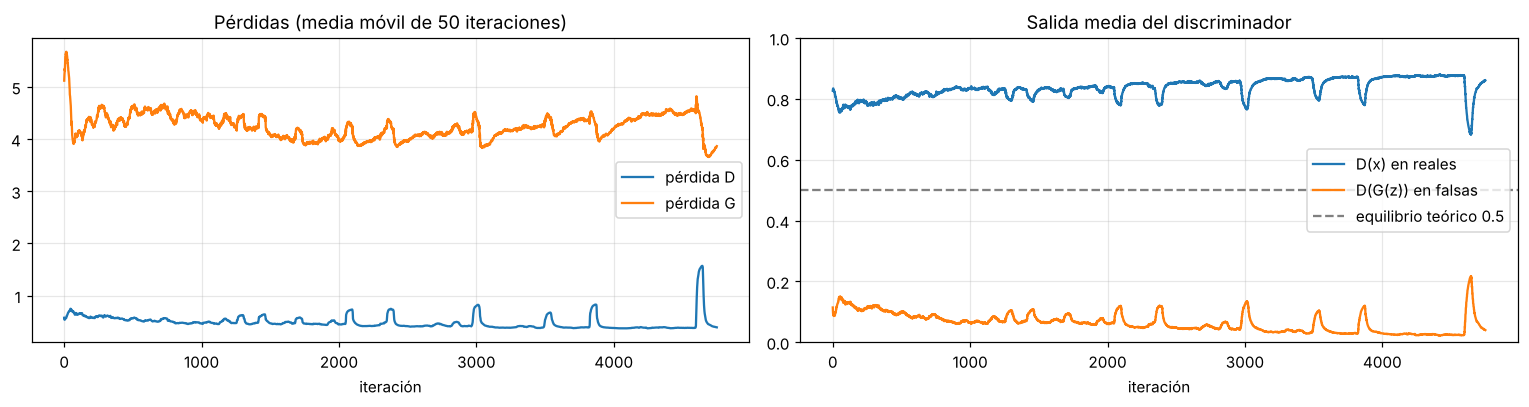

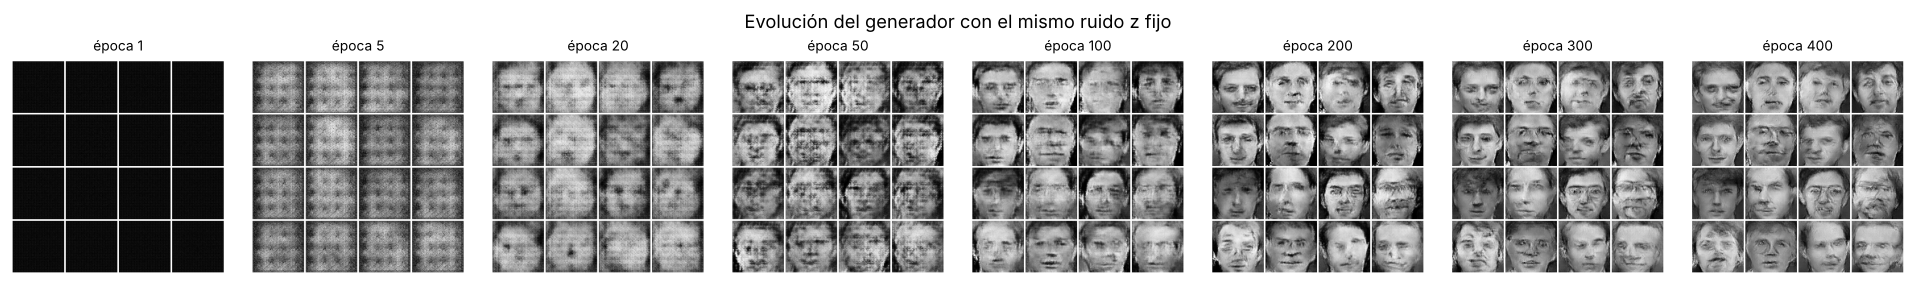

In [5]:
def smooth(v, k=50): return np.convolve(v, np.ones(k) / k, mode="valid")
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(smooth(hist["loss_D"]), label="pérdida D"); ax[0].plot(smooth(hist["loss_G"]), label="pérdida G")
ax[0].set_title("Pérdidas (media móvil de 50 iteraciones)"); ax[0].set_xlabel("iteración"); ax[0].legend()
ax[1].plot(smooth(hist["D_x"]), label="D(x) en reales"); ax[1].plot(smooth(hist["D_G_z"]), label="D(G(z)) en falsas")
ax[1].axhline(0.5, ls="--", c="gray", label="equilibrio teórico 0.5"); ax[1].set_ylim(0, 1)
ax[1].set_title("Salida media del discriminador"); ax[1].set_xlabel("iteración"); ax[1].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("figures/01_curvas_dcgan.png", bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, len(SNAP), figsize=(2.2 * len(SNAP), 2.6))
for a, e in zip(axes, SNAP):
    a.imshow(grid(snapshots[e][:16], 4), cmap="gray"); a.set_title(f"época {e}", fontsize=9); a.axis("off")
plt.suptitle("Evolución del generador con el mismo ruido z fijo"); plt.tight_layout()
plt.savefig("figures/01_evolucion.png", bbox_inches="tight"); plt.show()

## 5. Generación de rostros sintéticos

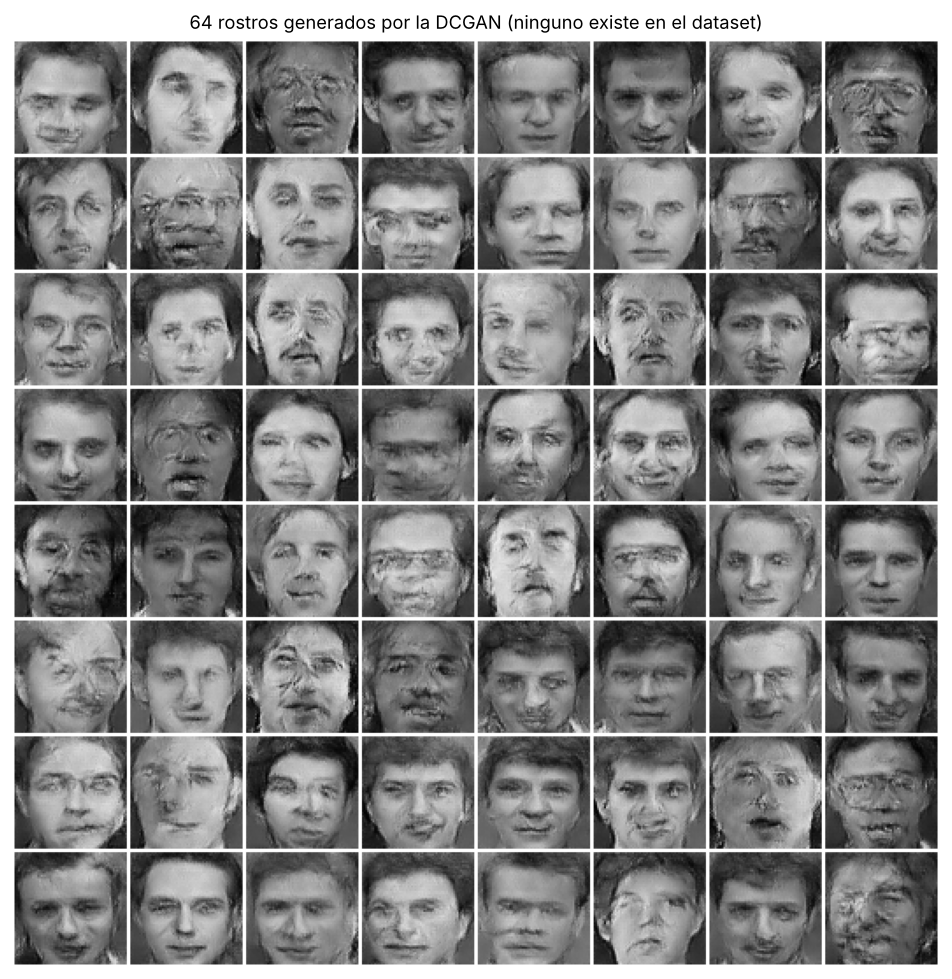

In [6]:
G.eval()
with torch.no_grad():
    samples = G(torch.randn(64, NZ, 1, 1, device=device)).cpu()
plt.figure(figsize=(9, 9)); plt.imshow(grid(samples, 8), cmap="gray"); plt.axis("off")
plt.title("64 rostros generados por la DCGAN (ninguno existe en el dataset)"); plt.tight_layout()
plt.savefig("figures/01_muestras_generadas.png", bbox_inches="tight"); plt.show()

## 6. Exploración del espacio latente
El generador define una función continua del espacio latente a las imágenes. Interpolar entre dos vectores *z* produce transiciones suaves entre rostros, lo que indica que la red aprendió una representación estructurada y no una tabla de imágenes memorizadas. Se usa interpolación **esférica** (slerp), adecuada para ruido gaussiano de alta dimensión.

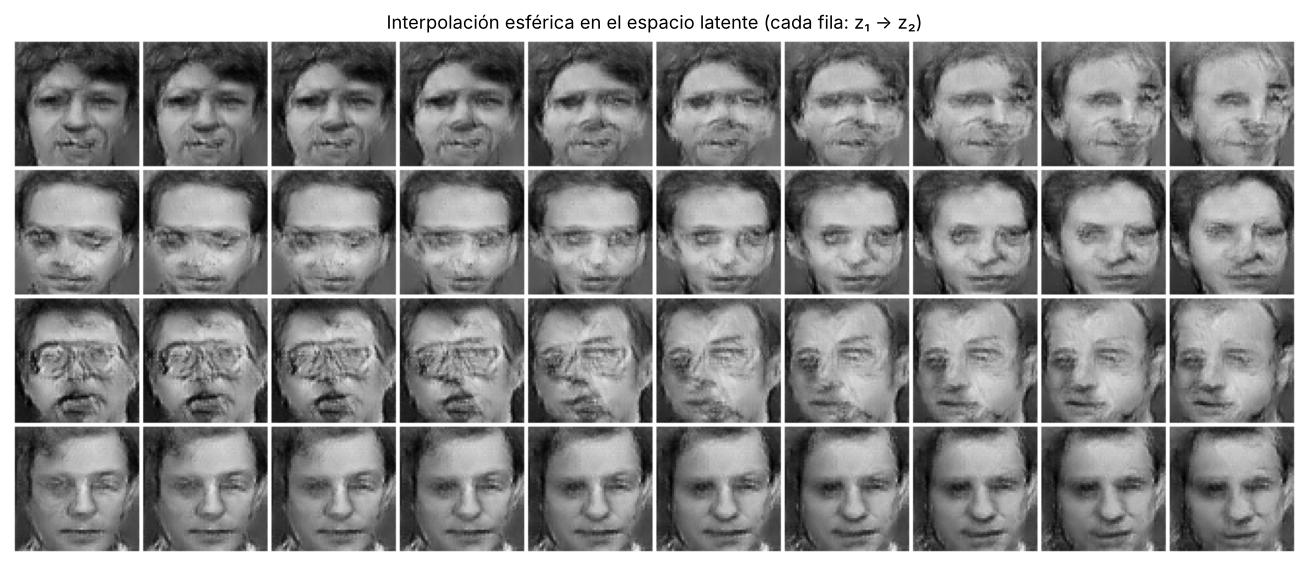

In [7]:
def slerp(a, b, t):
    a_n, b_n = a / a.norm(), b / b.norm()
    omega = torch.acos((a_n * b_n).sum().clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega)

torch.manual_seed(7)
rows = []
for _ in range(4):
    a, b = torch.randn(NZ, 1, 1), torch.randn(NZ, 1, 1)
    rows.append(torch.stack([slerp(a, b, t) for t in np.linspace(0, 1, 10)]))
with torch.no_grad():
    interp = G(torch.cat(rows).to(device)).cpu()
plt.figure(figsize=(12, 5.2)); plt.imshow(grid(interp, 10), cmap="gray"); plt.axis("off")
plt.title("Interpolación esférica en el espacio latente (cada fila: z₁ → z₂)"); plt.tight_layout()
plt.savefig("figures/01_interpolacion.png", bbox_inches="tight"); plt.show()

## 7. ¿Genera o memoriza? Vecino más cercano y diversidad
Con sólo 400 imágenes el riesgo es que G **copie** ejemplos del entrenamiento. Para cada rostro generado se busca la imagen real más cercana (distancia euclidiana en píxeles) y se compara con la distancia típica entre dos fotos reales distintas. También se mide la **diversidad** (distancia media entre pares) para detectar *mode collapse*.

{
 "epocas": 400,
 "iteraciones": 4800,
 "tiempo_min": 9.6,
 "params_G": 1099200,
 "params_D": 693632,
 "loss_D_final": 0.5106077955365181,
 "loss_G_final": 4.318868261307478,
 "D_x_final": 0.8504100028062239,
 "D_G_z_final": 0.04964769285044167,
 "nn_generada_media": 17.796005249023438,
 "nn_real_media": 12.438088417053223,
 "fraccion_generadas_mas_cerca_que_p5_real": 0.0,
 "diversidad_generadas": 27.092010498046875,
 "diversidad_reales": 27.255456924438477
}


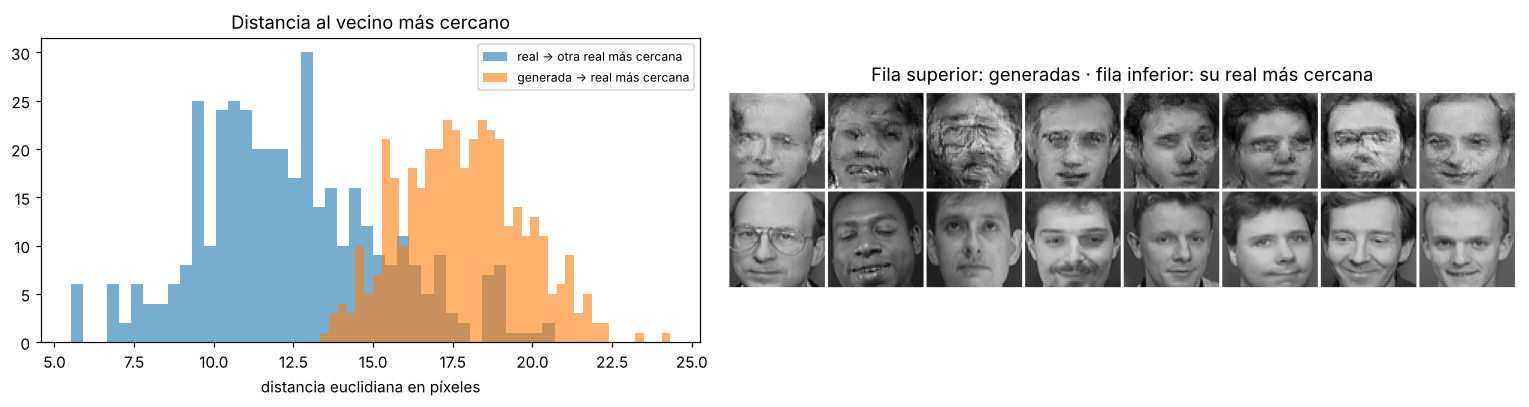

In [8]:
def flat(t): return t.reshape(len(t), -1)
with torch.no_grad():
    gen = G(torch.randn(400, NZ, 1, 1, device=device)).cpu()
d_gen_real = torch.cdist(flat(gen), flat(X))                       # (400 generadas, 400 reales)
nn_gen, nn_idx = d_gen_real.min(1)
d_rr = torch.cdist(flat(X), flat(X)); d_rr.fill_diagonal_(float("inf"))
nn_real = d_rr.min(1).values
div_gen = torch.pdist(flat(gen)).mean().item(); div_real = torch.pdist(flat(X)).mean().item()
summary = {"epocas": EPOCHS, "iteraciones": len(hist["loss_D"]), "tiempo_min": round(train_time / 60, 1),
           "params_G": n_params(G), "params_D": n_params(D),
           "loss_D_final": float(np.mean(hist["loss_D"][-500:])), "loss_G_final": float(np.mean(hist["loss_G"][-500:])),
           "D_x_final": float(np.mean(hist["D_x"][-500:])), "D_G_z_final": float(np.mean(hist["D_G_z"][-500:])),
           "nn_generada_media": nn_gen.mean().item(), "nn_real_media": nn_real.mean().item(),
           "fraccion_generadas_mas_cerca_que_p5_real": float((nn_gen < nn_real.quantile(0.05)).float().mean()),
           "diversidad_generadas": div_gen, "diversidad_reales": div_real}
print(json.dumps(summary, indent=1))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"width_ratios": [1, 1.2]})
ax[0].hist(nn_real.numpy(), bins=40, alpha=0.6, label="real → otra real más cercana")
ax[0].hist(nn_gen.numpy(), bins=40, alpha=0.6, label="generada → real más cercana")
ax[0].set_xlabel("distancia euclidiana en píxeles"); ax[0].set_title("Distancia al vecino más cercano"); ax[0].legend(fontsize=8)
pairs = torch.cat([gen[:8], X[nn_idx[:8]]])
ax[1].imshow(grid(pairs, 8), cmap="gray"); ax[1].axis("off")
ax[1].set_title("Fila superior: generadas · fila inferior: su real más cercana")
plt.tight_layout(); plt.savefig("figures/01_vecino_mas_cercano.png", bbox_inches="tight"); plt.show()
json.dump(summary, open("results/01_dcgan.json", "w"), indent=2)

## 8. Análisis
* **Entrenamiento adversarial.** En 4 800 iteraciones (400 épocas, 9.6 min en CPU) el generador pasó de ruido uniforme (época 1) a manchas con estructura de rostro (época 20) y a rostros reconocibles con ojos, nariz, boca, cabello e incluso gafas (épocas 100–400).
* **Equilibrio.** El juego no llegó al equilibrio teórico (D = 0.5): al final D(x) ≈ 0.85 y D(G(z)) ≈ 0.05, es decir, el discriminador sigue distinguiendo bien. Es lo habitual con un dataset pequeño, porque D termina reconociendo las 400 fotos reales. Los picos periódicos de la pérdida de D son episodios en que G encuentra imágenes que lo engañan y D se reajusta: la dinámica oscila en lugar de converger, un rasgo típico del entrenamiento adversarial.
* **Calidad.** Muchas muestras son rostros convincentes de 64×64. Otras presentan artefactos (ojos o gafas deformados, texturas repetidas), producto del poco dato y de la resolución.
* **Generación frente a memorización.** Las imágenes generadas están más lejos de su foto real más cercana (17.8 de distancia media) que dos fotos reales entre sí (12.4), y ninguna cae por debajo del percentil 5 de las distancias reales. G **no copia** el dataset: produce combinaciones nuevas.
* **Diversidad.** La distancia media entre pares generados (27.1) es prácticamente igual a la de los pares reales (27.3), así que **no hubo *mode collapse***. La interpolación en el espacio latente produce transiciones suaves (giro, gafas, expresión), señal de que G aprendió una representación continua.
* **Limitaciones.** 400 imágenes en escala de grises y 64×64 limitan el realismo. Con CelebA (≈ 200 000 rostros a color) y GPU, el mismo código produce rostros mucho más nítidos, y las GAN modernas (StyleGAN) llegan a 1024×1024.